# Block 0. Time audit

Checks that the time fields of the hotspot table are right and that `burn_date`
(06:00 to 06:00 local solar time) is a safe day key. Plan: `docs/eda-plan.md`, block 0.
Results and decisions: `docs/findings/00-time-audit.md`.

Local solar time = UTC hour + longitude / 15. Queries run in DuckDB so the table never loads in memory.

In [1]:
import warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "NASA_Data_Sources").is_dir())
TABLE = ROOT / "NASA_Data_Sources" / "processed" / "hotspots"

con = duckdb.connect()
con.execute("SET TimeZone='UTC'")
con.execute(f"CREATE VIEW h AS SELECT * FROM read_parquet('{TABLE}/*/*.parquet', hive_partitioning=true)")


def q(sql: str) -> pd.DataFrame:
    return con.execute(sql).df()


pd.set_option("display.width", 200, "display.max_columns", None)
warnings.filterwarnings("ignore", category=DeprecationWarning)  # duckdb -> pandas noise
q("SELECT count(*) AS rows, min(acq_datetime) AS first, max(acq_datetime) AS last FROM h")

,rows,first,last
0,8042380,2000-11-01 02:31:00+00:00,2026-11-14 13:37:00+00:00


## 0.1 The source is UTC

If `acq_time` is UTC, local solar time must peak at the known overpass hours of each satellite.

In [2]:
q("""
SELECT count(*) FILTER (WHERE NOT regexp_matches(acq_time, '^([01][0-9]|2[0-3])[0-5][0-9]$')) AS bad_format,
       count(*) FILTER (WHERE acq_time IS NULL) AS missing, min(acq_time) AS min, max(acq_time) AS max
FROM h
""")

,bad_format,missing,min,max
0,0,0,0005,2356


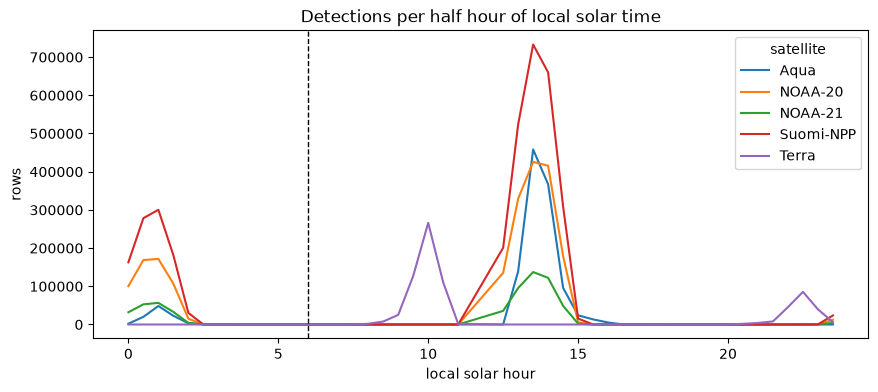

,satellite,solar_h,n
11,Aqua,13.5,458188
12,Aqua,14.0,367186
26,NOAA-20,13.5,425725
27,NOAA-20,14.0,415602
41,NOAA-21,13.5,137324
42,NOAA-21,14.0,122099
56,Suomi-NPP,13.5,732991
57,Suomi-NPP,14.0,659871
71,Terra,9.5,127062
72,Terra,10.0,266195


In [3]:
half = q("""
SELECT satellite, floor(solar_time_h * 2) / 2 AS solar_h, count(*) AS n
FROM h GROUP BY ALL ORDER BY ALL
""")
ax = half.pivot(index="solar_h", columns="satellite", values="n").fillna(0).plot(figsize=(10, 4))
ax.axvline(6, color="k", ls="--", lw=1)
ax.set(title="Detections per half hour of local solar time", xlabel="local solar hour", ylabel="rows")
plt.show()
half.sort_values("n", ascending=False).groupby("satellite").head(2).sort_values(["satellite", "solar_h"])

## 0.2 Rows that change day, month and year under each convention

In [4]:
q("""
SELECT satellite, count(*) AS rows,
       round(100 * avg((local_date <> acq_date)::INT), 2) AS pct_civil_vs_utc,
       round(100 * avg((burn_date <> acq_date)::INT), 2) AS pct_burn_vs_utc,
       round(100 * avg((burn_date <> local_date)::INT), 2) AS pct_burn_vs_civil
FROM h GROUP BY 1 ORDER BY 1
""")

,satellite,rows,pct_civil_vs_utc,pct_burn_vs_utc,pct_burn_vs_civil
0,Aqua,1201272,0.00,8.19,8.19
1,NOAA-20,2066449,0.00,27.86,27.86
2,NOAA-21,624426,0.00,29.29,29.29
3,Suomi-NPP,3419056,0.00,28.59,28.59
4,Terra,731177,14.15,26.11,11.96


In [5]:
q("""
SELECT sum((date_trunc('month', local_date) <> date_trunc('month', acq_date))::INT) AS civil_moves_month,
       sum((year(local_date) <> year(acq_date))::INT) AS civil_moves_year,
       sum((date_trunc('month', burn_date) <> date_trunc('month', acq_date))::INT) AS burn_moves_month,
       sum((burn_year <> year(acq_date))::INT) AS burn_moves_year,
       sum((season_year <> CASE WHEN month(acq_date) >= 7 THEN year(acq_date) ELSE year(acq_date) - 1 END)::INT)
           AS burn_moves_season
FROM h
""")

,civil_moves_month,civil_moves_year,burn_moves_month,burn_moves_year,burn_moves_season
0,3755.0,386.0,67658.0,6257.0,1734.0


Civil midnight splits the Terra night pass (MODIS only); solar midnight splits the VIIRS night pass.

In [6]:
q("""
SELECT country, civil_hour, count(*) AS rows
FROM (SELECT country, hour(local_wall_time) AS civil_hour FROM h
      WHERE satellite = 'Terra' AND pass_slot = 'night_pass')
WHERE civil_hour IN (22, 23, 0, 1)
GROUP BY 1, 2 ORDER BY country, (civil_hour + 12) % 24
""")

,country,civil_hour,rows
0,Argentina,22,8603
1,Argentina,23,86043
2,Argentina,0,63529
3,Argentina,1,3756
4,Chile,22,721
5,Chile,23,6755
6,Chile,0,16812
7,Chile,1,3367


In [7]:
q("""
SELECT instrument, count(*) AS night_rows,
       round(100 * avg((solar_time_h >= 18)::INT), 2) AS pct_before_solar_midnight
FROM h WHERE pass_slot = 'night_pass' GROUP BY 1
""")

,instrument,night_rows,pct_before_solar_midnight
0,MODIS,289292,65.99
1,VIIRS,1736118,2.39


## 0.3 The 06:00 cut is empty

Closest detections to the cut, per satellite and latitude band (passes spread more in Patagonia).

In [8]:
q("SELECT count(*) AS rows_between_0430_and_0700 FROM h WHERE solar_time_h >= 4.5 AND solar_time_h < 7")

,rows_between_0430_and_0700
0,0


In [9]:
q("""
SELECT satellite, CAST(floor(latitude / 10) * 10 AS INT) AS lat_band,
       round(max(solar_time_h) FILTER (WHERE solar_time_h < 6), 2) AS last_before_cut,
       round(min(solar_time_h) FILTER (WHERE solar_time_h >= 6), 2) AS first_after_cut,
       count(*) AS rows
FROM h GROUP BY ALL ORDER BY ALL
""")

,satellite,lat_band,last_before_cut,first_after_cut,rows
0,Aqua,-60,2.07,13.11,818
1,Aqua,-50,3.32,13.07,18410
2,Aqua,-40,3.87,13.02,363017
3,Aqua,-30,4.27,12.99,818648
4,Aqua,-20,2.28,13.06,379
5,NOAA-20,-60,2.26,12.62,4208
6,NOAA-20,-50,2.13,12.67,36847
7,NOAA-20,-40,2.22,12.66,699238
8,NOAA-20,-30,2.30,12.64,1324550
9,NOAA-20,-20,2.15,12.65,1606


In [10]:
q("""
SELECT burn_year, round(max(solar_time_h) FILTER (WHERE solar_time_h < 6), 2) AS last_before_cut,
       round(min(solar_time_h) FILTER (WHERE solar_time_h >= 6), 2) AS first_after_cut
FROM h GROUP BY 1 ORDER BY 1
""").T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26
burn_year,2000.00,2001.00,2002.00,2003.00,2004.00,2005.00,2006.00,2007.00,2008.00,2009.00,2010.00,2011.00,2012.00,2013.00,2014.00,2015.00,2016.0,2017.00,2018.00,2019.00,2020.00,2021.00,2022.00,2023.00,2024.00,2025.00,2026.00
last_before_cut,0.03,0.09,2.07,2.04,2.06,2.04,2.11,2.09,2.11,2.16,2.10,2.10,2.15,2.20,2.32,2.26,2.2,2.21,2.21,2.17,2.17,2.18,2.23,2.38,2.77,3.51,4.27
first_after_cut,9.33,8.81,9.07,9.11,8.68,9.02,9.09,8.82,9.03,9.04,8.83,8.93,8.98,9.09,9.07,8.99,9.0,9.14,9.05,9.08,9.13,9.01,8.83,8.68,8.50,7.60,7.49


## 0.4 `pass_slot` against `daynight`

`daynight` follows the sun angle, `pass_slot` follows the orbit. They disagree at high latitudes.

In [11]:
q("""
SELECT instrument, pass_slot, daynight, count(*) AS rows,
       round(min(latitude), 1) AS lat_min, round(max(latitude), 1) AS lat_max
FROM h GROUP BY ALL ORDER BY ALL
""")

,instrument,pass_slot,daynight,rows,lat_min,lat_max
0,MODIS,day_pass,D,1643133,-54.9,-17.7
1,MODIS,day_pass,N,24,-48.8,-35.4
2,MODIS,night_pass,N,289292,-54.6,-18.4
3,VIIRS,day_pass,D,4373790,-54.8,-17.6
4,VIIRS,day_pass,N,23,-53.7,-52.2
5,VIIRS,night_pass,N,1736118,-55.3,-17.6


## 0.5 Orbit drift of Terra and Aqua

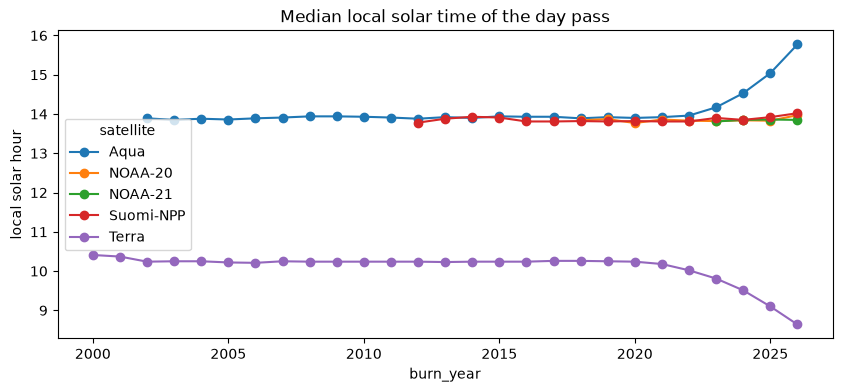

burn_year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
satellite,,,,,,,,,,,,,,,,,,,,,,,,,,,
Aqua,NaN,NaN,13.89,13.85,13.88,13.86,13.89,13.91,13.94,13.94,13.93,13.91,13.88,13.92,13.90,13.94,13.93,13.93,13.89,13.92,13.90,13.92,13.96,14.17,14.53,15.04,15.77
NOAA-20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.84,13.87,13.77,13.86,13.83,13.82,13.84,13.83,13.97
NOAA-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.81,13.85,13.86,13.85
Suomi-NPP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.78,13.88,13.93,13.91,13.81,13.81,13.82,13.81,13.82,13.81,13.81,13.90,13.85,13.92,14.02
Terra,10.41,10.37,10.24,10.25,10.25,10.22,10.21,10.25,10.24,10.24,10.24,10.24,10.24,10.23,10.24,10.24,10.24,10.26,10.26,10.25,10.24,10.18,10.02,9.81,9.51,9.10,8.64


In [12]:
drift = q("""
SELECT satellite, burn_year, round(median(solar_time_h), 2) AS day_pass_solar_h
FROM h WHERE pass_slot = 'day_pass' GROUP BY ALL ORDER BY ALL
""").pivot(index="burn_year", columns="satellite", values="day_pass_solar_h")
ax = drift.plot(figsize=(10, 4), marker="o")
ax.set(title="Median local solar time of the day pass", ylabel="local solar hour")
plt.show()
drift.T

In [13]:
q("""
SELECT satellite, CAST(floor(latitude / 15) * 15 AS INT) AS lat_band,
       round(median(solar_time_h) FILTER (WHERE burn_year BETWEEN 2012 AND 2021), 2) AS solar_h_2012_2021,
       round(median(solar_time_h) FILTER (WHERE burn_year = 2026), 2) AS solar_h_2026
FROM h WHERE pass_slot = 'day_pass' AND satellite IN ('Terra', 'Aqua', 'Suomi-NPP', 'NOAA-20')
GROUP BY ALL ORDER BY ALL
""")

,satellite,lat_band,solar_h_2012_2021,solar_h_2026
0,Aqua,-60,14.21,15.99
1,Aqua,-45,13.98,15.70
2,Aqua,-30,13.88,15.80
3,NOAA-20,-60,14.05,14.03
4,NOAA-20,-45,13.90,14.02
5,NOAA-20,-30,13.80,13.95
6,Suomi-NPP,-60,14.14,14.22
7,Suomi-NPP,-45,13.92,14.08
8,Suomi-NPP,-30,13.80,13.99
9,Terra,-60,10.01,8.57


## 0.6 Civil time

In [14]:
q("""
SELECT country, tz_name, count(*) AS rows, list(DISTINCT utc_offset_min ORDER BY utc_offset_min) AS offsets_min,
       count(DISTINCT admin1) AS regions
FROM h GROUP BY ALL ORDER BY country, rows DESC
""")

,country,tz_name,rows,offsets_min,regions
0,Argentina,America/Argentina/Cordoba,4962640,"[-180, -120]",8
1,Argentina,America/Argentina/Salta,1030332,"[-180, -120]",4
2,Argentina,America/Argentina/Buenos_Aires,336347,"[-180, -120]",2
3,Argentina,America/Argentina/Tucuman,166083,"[-240, -180, -120]",1
4,Argentina,America/Argentina/San_Luis,149777,"[-240, -180, -120]",1
5,Argentina,America/Argentina/Mendoza,124802,"[-240, -180, -120]",1
6,Argentina,America/Argentina/Catamarca,114691,"[-240, -180, -120]",2
7,Argentina,America/Argentina/Jujuy,69967,"[-180, -120]",1
8,Argentina,America/Argentina/La_Rioja,56074,"[-240, -180, -120]",1
9,Argentina,America/Argentina/San_Juan,52707,"[-240, -180, -120]",1


## 0.7 Coverage per satellite

In [15]:
q("""
SELECT satellite, min(acq_datetime) AS first, max(acq_datetime) AS last,
       min(burn_date) AS first_burn_date, max(burn_date) AS last_burn_date, count(*) AS rows
FROM h GROUP BY 1 ORDER BY first
""")

,satellite,first,last,first_burn_date,last_burn_date,rows
0,Terra,2000-11-01 02:31:00+00:00,2026-11-14 13:37:00+00:00,2000-10-31,2026-11-14,731177
1,Aqua,2002-07-04 17:23:00+00:00,2026-11-14 08:34:00+00:00,2002-07-04,2026-11-13,1201272
2,Suomi-NPP,2012-01-20 04:55:00+00:00,2026-11-02 04:23:00+00:00,2012-01-19,2026-11-01,3419056
3,NOAA-20,2018-04-01 05:15:00+00:00,2026-11-14 06:01:00+00:00,2018-03-31,2026-11-13,2066449
4,NOAA-21,2023-03-01 03:11:00+00:00,2026-11-14 06:41:00+00:00,2023-02-28,2026-11-13,624426


In [16]:
q("""
SELECT acq_date, satellite, count(*) AS rows FROM h
WHERE acq_date >= DATE '2026-10-30' GROUP BY ALL ORDER BY ALL
""").pivot(index="acq_date", columns="satellite", values="rows").fillna(0).astype(int)

satellite,Aqua,NOAA-20,NOAA-21,Suomi-NPP,Terra
acq_date,,,,,
2026-10-30,25,600,812,587,28
2026-10-31,160,572,607,766,83
2026-11-01,13,244,162,222,42
2026-11-02,33,231,169,3,23
2026-11-03,108,212,273,0,39
2026-11-04,11,273,248,0,39
2026-11-05,181,89,243,0,113
2026-11-06,92,640,476,0,60
2026-11-07,16,521,195,0,25


## 0.8 Calendars: calendar year against season, ISO week against fixed bins

In [17]:
q("""
SELECT sum((weekofyear(burn_date) = 53)::INT) AS rows_in_iso_week_53,
       sum((isoyear(burn_date) <> burn_year)::INT) AS rows_iso_year_differs,
       sum((dayofyear(burn_date) > 364)::INT) AS rows_after_day_364,
       count(*) AS rows
FROM h
""")

,rows_in_iso_week_53,rows_iso_year_differs,rows_after_day_364,rows
0,8212.0,26960.0,24618.0,8042380


In [18]:
q("""
WITH cal AS (SELECT burn_year AS y, count(*) AS calendar_year_rows FROM h GROUP BY 1),
     sea AS (SELECT season_year AS y, count(*) AS season_rows FROM h GROUP BY 1)
SELECT y AS year, calendar_year_rows, season_rows FROM cal FULL JOIN sea USING (y) ORDER BY y
""").T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26
year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
calendar_year_rows,7680,33134,62429,122720,106387,78322,90721,84867,113176,90226,69794,84052,280796,334593,195402,240046,271455,330768,413616,429783,1070208,511702,767192,647518,586938,636490,382365
season_rows,20809,30425,78018,127846,98304,80639,81586,102811,103920,78699,71674,161557,268125,325669,219458,200153,348327,336055,381189,619893,892308,716487,741593,513691,710331,545685,187128


## 0.9 Sensitivity of the final metrics to the day convention

In [19]:
monthly = q("""
WITH u AS (SELECT instrument, date_trunc('month', acq_date) AS m, count(*) AS n_utc FROM h GROUP BY ALL),
     b AS (SELECT instrument, date_trunc('month', burn_date) AS m, count(*) AS n_burn FROM h GROUP BY ALL)
SELECT instrument, m, coalesce(n_utc, 0) AS n_utc, coalesce(n_burn, 0) AS n_burn
FROM u FULL JOIN b USING (instrument, m)
""")
monthly["rel_diff_pct"] = 100 * (monthly.n_burn - monthly.n_utc) / monthly.n_utc.clip(lower=1)
big = monthly[monthly.n_utc >= 1000]
big.groupby("instrument").rel_diff_pct.describe(percentiles=[0.5, 0.95]).round(2)

,count,mean,std,min,50%,95%,max
instrument,,,,,,,
MODIS,301.0,-0.08,1.21,-8.48,0.00,1.36,5.45
VIIRS,179.0,-0.06,1.49,-8.14,0.03,1.83,6.02


In [20]:
ranks = q("""
WITH u AS (SELECT instrument, year(acq_date) AS y, count(*) AS n FROM h GROUP BY ALL),
     b AS (SELECT instrument, burn_year AS y, count(*) AS n FROM h GROUP BY ALL)
SELECT instrument, y, u.n AS n_utc, b.n AS n_burn,
       rank() OVER (PARTITION BY instrument ORDER BY u.n DESC) AS rank_utc,
       rank() OVER (PARTITION BY instrument ORDER BY b.n DESC) AS rank_burn
FROM u JOIN b USING (instrument, y)
""")
print("years whose rank changes:", int((ranks.rank_utc != ranks.rank_burn).sum()), "of", len(ranks))
ranks[ranks.rank_burn <= 5].sort_values(["instrument", "rank_burn"])

years whose rank changes: 2 of 42


,instrument,y,n_utc,n_burn,rank_utc,rank_burn
0,MODIS,2020,132550,132555,1,1
1,MODIS,2003,122696,122720,2,2
2,MODIS,2008,113140,113176,3,3
3,MODIS,2004,106407,106387,4,4
4,MODIS,2006,90718,90721,5,5
27,VIIRS,2020,937593,937653,1,1
28,VIIRS,2022,682760,682197,2,2
29,VIIRS,2023,583384,583152,3,3
30,VIIRS,2025,581530,581625,4,4
31,VIIRS,2024,530515,530603,5,5


Fire-days (0.25° cell × day with at least one detection): the metric most exposed to the day key.

In [21]:
q("""
SELECT instrument,
       count(DISTINCT (floor(latitude * 4), floor(longitude * 4), acq_date)) AS fire_days_utc,
       count(DISTINCT (floor(latitude * 4), floor(longitude * 4), local_date)) AS fire_days_civil,
       count(DISTINCT (floor(latitude * 4), floor(longitude * 4), burn_date)) AS fire_days_burn
FROM h WHERE burn_year BETWEEN 2019 AND 2021 GROUP BY 1
""").assign(
    civil_vs_burn_pct=lambda d: (100 * (d.fire_days_civil / d.fire_days_burn - 1)).round(2),
    utc_vs_burn_pct=lambda d: (100 * (d.fire_days_utc / d.fire_days_burn - 1)).round(2),
)

,instrument,fire_days_utc,fire_days_civil,fire_days_burn,civil_vs_burn_pct,utc_vs_burn_pct
0,VIIRS,266676,266676,262970,1.41,1.41
1,MODIS,96251,96616,96443,0.18,-0.20
